# Competitive Influence Maximization on a 1,000-Node Synthetic Signed Network
## SSA O1/O4/O6 vs. Notebook Baselines and FIBM

**Experiment:** `benchmark_1000_synthetic`  
**Network:** 1,000 nodes, 7,500 directed trust arcs, influence direction reversed (`target → source`)  
**Primary metric:** Net Advantage = `Spread_A − Spread_B` (higher is better)  
**Secondary metrics:** `Spread_A`, `Spread_B`, `Blocked_B`, runtime  
**Monte Carlo:** 15 optimization seeds; 100 common final-evaluation seeds  
**Swap refinement:** excluded by instruction

This notebook is the 1,000-node synthetic version of the completed benchmark. It uses the existing 1,000-node synthetic trust network (`data/synthetic_network_1000_7500.csv`), the corrected trust→influence reversal, the validated algorithms, and the paper-based FIBM fairness baseline.

> **Important:** the previously completed 5,000-node benchmark results are **not** reused here. They belong to a different graph. This notebook reads the separate `benchmark_1000_synthetic/` run, which was computed on exactly the 1,000-node graph.
>
> **Execution policy.** The default is `load_existing`. No SSA, FIBM, baseline or diffusion simulation is launched unless the guarded execution mode is explicitly changed.


## 1. Research overview

Competitive influence maximization studies how a campaign (Rumor A / truth) should choose seed nodes against an adversarial campaign (Rumor B). This project uses a **signed trust network**:

- the CSV records trust arcs `source → target`;
- the influence graph is the exact reverse, `target → source`;
- positive trust arcs preserve the rumor;
- negative trust arcs flip the rumor;
- transmission probability is determined by the absolute trust strength.

The notebook compares SSA O1, O4 and O6 in SSA-only mode against the earlier notebook baselines and a fairness-aware influence-blocking baseline. The external ranking metric is Net Advantage for every method.


## 2. Research objectives

1. Verify that the 1,000-node, 7,500-edge synthetic network and its reversed influence direction are correct.
2. Document the signed-edge representation, trust-to-probability mapping, competitive Maki–Thompson diffusion and Rumor A/B mechanics.
3. Expose the actual implementations of SSA O1/O4/O6, the notebook baselines and FIBM.
4. Reuse the saved 1,000-node seed selections and Monte Carlo evaluations without recomputation.
5. Rank methods by Net Advantage while reporting Spread_A and Spread_B separately.
6. Quantify scenario/K sensitivity, win/tie/loss behaviour, runtime and uncertainty.
7. Produce clean, publication-quality Net Advantage charts for B1–B4.
8. State limitations and give a defensible recommendation.

SSA + Swap and all swap-based post-processing are excluded. Existing Swap implementations and historical results remain untouched elsewhere in the project.


## 3. Experimental methodology

### 3.1 Network and influence direction

The trust CSV has columns `source, target, rating, probability, strength, polarity`. The influence graph reverses every arc exactly once. All algorithms and the diffusion engine use the reversed graph.

### 3.2 Diffusion model

Finite-contact competitive Maki–Thompson variant:

- states: `0` ignorant, `1` A-spreader, `2` B-spreader, `3` A-stifler, `4` B-stifler;
- each spreader contacts one uniformly random uncontacted outgoing influence neighbour per round;
- no uncontacted neighbour, or a non-ignorant target, makes the spreader a stifler;
- otherwise it transmits with the edge probability;
- a negative edge flips A↔B; a positive edge preserves the rumor;
- proposals are resolved by highest edge strength; different-rumor ties are random;
- `Spread_A` counts states 1+3; `Spread_B` counts 2+4.

### 3.3 Opponents and budgets

- B1 Random, B2 Degree, B3 Positive PageRank, B4 Community-concentrated.
- B orders have length 50 and are nested across K; the K-seed set is the prefix.
- K = 10, 20, 30, 40, 50.
- Optimization MC = 15 common seeds; final evaluation MC = 100 common seeds.

### 3.4 Primary metric

```
Net Advantage = Spread_A − Spread_B
```

The ranking is by Net Advantage. `Spread_A` and `Spread_B` explain the result. A method is not declared best from `Spread_A` alone or from a blocking metric alone.


## 4. Imports and configuration

The notebook imports the completed modules from the experiment directory and project root. It does not reimplement validated algorithms.

| Mode | Behaviour |
|---|---|
| `load_existing` | Default. Loads and validates the saved 1,000-node results; no simulations. |
| `run_missing` | Computes only missing/invalid cells after explicit opt-in. |
| `force_rerun` | Writes selected reruns to a new timestamped directory; never overwrites the saved run. |

`ALLOW_MISSING_RUNS` and `ALLOW_FORCE_RERUN` are safety gates.


In [1]:
%matplotlib inline

from pathlib import Path
import inspect
import json
import math
import sys
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image

# ---------------------------------------------------------------------------
# Locate the experiment directory robustly.
# ---------------------------------------------------------------------------
CWD = Path.cwd().resolve()
if (CWD / "config" / "benchmark_1000_synthetic_config.json").exists():
    EXPERIMENT_DIR = CWD
elif (CWD / "benchmark_ssa_baselines_fairness" / "config" / "benchmark_1000_synthetic_config.json").exists():
    EXPERIMENT_DIR = CWD / "benchmark_ssa_baselines_fairness"
else:
    EXPERIMENT_DIR = Path(
        "/home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/"
        "experiments/benchmark_ssa_baselines_fairness"
    )

PROJECT_ROOT = EXPERIMENT_DIR.parents[1]
for path in (EXPERIMENT_DIR, PROJECT_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from algorithms.core import (  # noqa: E402
    cell_signature,
    load_verified_network,
    make_evaluator,
    opponent_orders,
)
from algorithms.fibmm import FIBMMConfig  # noqa: E402
from algorithms.notebook_baselines import (  # noqa: E402
    celf_lazy_greedy,
    compute_ncge_centrality_scores,
    compute_signed_pagerank,
    crieg_seeds,
    ncge_candidate_pool,
    random_seeds,
    run_ssa_notebook,
    signed_ga_seeds,
    signed_pagerank_seeds,
    top_degree_seeds,
)
from common.objectives import VARIANTS, budget_coefficients  # noqa: E402
from common.ssa import run_discrete_ssa  # noqa: E402
import notebook_analysis as na  # noqa: E402

# ---------------------------------------------------------------------------
# Execution policy.  Defaults are intentionally safe.
# ---------------------------------------------------------------------------
EXECUTION_MODE = "load_existing"   # "load_existing" | "run_missing" | "force_rerun"
ALLOW_MISSING_RUNS = False
ALLOW_FORCE_RERUN = False
FORCE_METHODS = []
FORCE_SCENARIOS = []
FORCE_K = []
SAVE_NOTEBOOK_FIGURES = True
SIMULATION_LAUNCHED = False

CONFIG_PATH = EXPERIMENT_DIR / "config" / "benchmark_1000_synthetic_config.json"
RESULTS_ROOT = EXPERIMENT_DIR / "benchmark_1000_synthetic" / "raw_results"
NOTEBOOK_FIG_DIR = EXPERIMENT_DIR / "figures" / "notebook_1000"
if SAVE_NOTEBOOK_FIGURES:
    NOTEBOOK_FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.7,
})
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

print("Experiment directory:", EXPERIMENT_DIR)
print("Configuration:", CONFIG_PATH)
print("Saved 1,000-node results:", RESULTS_ROOT)
print("Execution mode:", EXECUTION_MODE)


Experiment directory: /home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness
Configuration: /home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness/config/benchmark_1000_synthetic_config.json
Saved 1,000-node results: /home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness/benchmark_1000_synthetic/raw_results
Execution mode: load_existing


## 5. Network loading and verification

`load_verified_network` checks the file SHA-256, trust semantic hash, influence semantic hash, node count, arc count and the full trust→influence reversal relation. A mismatch stops the notebook.  The 1,000-node network has 2 reciprocal trust pairs, so 4 trust edges also appear in the reverse direction; this is expected and is not a direction failure.  The full reversal check still requires zero missing and zero extra reversed edges.


In [2]:
config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
trust_df, G, nodes, network_meta = load_verified_network(config)

network_summary = pd.DataFrame([
    {"property": "nodes", "value": network_meta["nodes"]},
    {"property": "trust arcs", "value": network_meta["trust_arcs"]},
    {"property": "influence arcs", "value": network_meta["influence_arcs"]},
    {"property": "influence direction", "value": network_meta["influence_direction"]},
    {"property": "file SHA-256", "value": network_meta["file_sha256"]},
    {"property": "trust semantic SHA-256", "value": network_meta["trust_semantic_sha256"]},
    {"property": "influence semantic SHA-256", "value": network_meta["influence_semantic_sha256"]},
])
display(network_summary)

direction = network_meta["direction_check"]
assert direction["all_trust_edges_reversed"] is True
assert direction["missing_reversed_edges"] == 0
assert direction["extra_influence_edges"] == 0
assert direction["same_direction_edges"] == 2 * direction["reciprocal_trust_pairs"]
print("1,000-node network identity and direction check: PASS")
print("Reciprocal trust pairs:", direction["reciprocal_trust_pairs"],
      "| same-direction edges (both directions of reciprocal pairs):",
      direction["same_direction_edges"])


,property,value
0,nodes,1000
1,trust arcs,7500
2,influence arcs,7500
3,influence direction,reverse_of_trust (target_to_source)
4,file SHA-256,659d4fa65a3904c96e5653c16f3357b95a43a004408441...
5,trust semantic SHA-256,461febf43a90332f04f13d706cf8f34579202aab120a77...
6,influence semantic SHA-256,0c0f4e1f1d8a3abc0e2765941e94cfe233efbe32246c5b...


1,000-node network identity and direction check: PASS
Reciprocal trust pairs: 2 | same-direction edges (both directions of reciprocal pairs): 4


## 6. Network characteristics

The network is signed: every arc has a polarity and trust strength. Strength maps to a transmission probability; polarity controls whether a successful transmission preserves or flips the rumor.


In [3]:
validation = network_meta["trust_validation"]
characteristics = pd.DataFrame([
    {"characteristic": "positive arcs", "value": validation["n_positive"]},
    {"characteristic": "negative arcs", "value": validation["n_negative"]},
    {"characteristic": "probability 0.1", "value": validation["probability_class_counts"]["0.1"]},
    {"characteristic": "probability 0.5", "value": validation["probability_class_counts"]["0.5"]},
    {"characteristic": "probability 0.9", "value": validation["probability_class_counts"]["0.9"]},
    {"characteristic": "out-degree min/mean/max", "value": f"{validation['out_degree']['min']} / {validation['out_degree']['mean']:.2f} / {validation['out_degree']['max']}"},
    {"characteristic": "in-degree min/mean/max", "value": f"{validation['in_degree']['min']} / {validation['in_degree']['mean']:.2f} / {validation['in_degree']['max']}"},
    {"characteristic": "weak components", "value": validation["n_weak_components"]},
    {"characteristic": "strong components", "value": validation["n_strong_components"]},
    {"characteristic": "self-loops", "value": validation["n_self_loops"]},
    {"characteristic": "duplicate directed arcs", "value": validation["n_duplicate_arcs"]},
])
display(characteristics)


,characteristic,value
0,positive arcs,3720
1,negative arcs,3780
2,probability 0.1,2278
3,probability 0.5,2950
4,probability 0.9,2272
5,out-degree min/mean/max,0 / 7.50 / 77
6,in-degree min/mean/max,1 / 7.50 / 67
7,weak components,1
8,strong components,3
9,self-loops,0


## 7. Diffusion model

The production simulator is the persistent C++ engine. It is built once for the graph and reused for every Monte Carlo replicate. The notebook instantiates it but does not run a simulation in load-existing mode.

The model is a finite-contact Maki–Thompson variant. A spreader contacts each outgoing arc at most once; an ignorant target may be activated by the strongest successful proposal in a round; a negative edge flips the transmitted rumor. Stiflers remain counted in their side's final spread.


In [4]:
simulator, evaluator = make_evaluator(G, nodes, network_meta, config)
display(pd.DataFrame([
    {"component": "C++ diffusion engine", "value": "ready"},
    {"component": "engine nodes", "value": simulator.num_nodes},
    {"component": "engine edges", "value": simulator.num_edges},
    {"component": "simulation launched in this cell", "value": False},
]))


,component,value
0,C++ diffusion engine,ready
1,engine nodes,1000
2,engine edges,7500
3,simulation launched in this cell,False


## 8. Opponent strategies B1–B4

Rumor B is fixed before Rumor A is selected. The four opponent orders are length 50 and nested across K. The same B seed set is used for every A method within a scenario/K cell.

| Scenario | Construction |
|---|---|
| B1 Random | uniform random sample, seed `master_seed + 810001` |
| B2 Degree | influence out-degree descending, ties by node id |
| B3 Positive PageRank | PageRank on the positive-only influence subgraph, weight = probability |
| B4 Community | Louvain on the undirected influence projection, largest community, degree ranking |


In [5]:
orders = opponent_orders(G, nodes, config)
opponent_rows = []
for sid in config["scenarios"]:
    order = orders[sid]
    assert len(order) == 50 and len(set(order)) == 50
    for k in config["k_values"]:
        B = order[:k]
        assert len(B) == k and len(set(B)) == k
        opponent_rows.append({"scenario": sid, "K": k, "B_seed_count": len(B), "B_seeds": json.dumps(B)})
opponent_table = pd.DataFrame(opponent_rows)
display(opponent_table[opponent_table["K"].isin([10, 50])].reset_index(drop=True))
print("Nested opponent orders verified for all scenarios and K values.")


,scenario,K,B_seed_count,B_seeds
0,B1,10,10,"[271, 382, 891, 972, 310, 288, 584, 268, 231, ..."
1,B1,50,50,"[271, 382, 891, 972, 310, 288, 584, 268, 231, ..."
2,B2,10,10,"[2, 5, 7, 4, 10, 16, 1, 0, 8, 3]"
3,B2,50,50,"[2, 5, 7, 4, 10, 16, 1, 0, 8, 3, 9, 19, 13, 21..."
4,B3,10,10,"[5, 2, 8, 0, 14, 11, 4, 10, 21, 1]"
5,B3,50,50,"[5, 2, 8, 0, 14, 11, 4, 10, 21, 1, 3, 7, 24, 1..."
6,B4,10,10,"[16, 1, 43, 27, 22, 37, 20, 24, 39, 153]"
7,B4,50,50,"[16, 1, 43, 27, 22, 37, 20, 24, 39, 153, 40, 4..."


Nested opponent orders verified for all scenarios and K values.


## 9. Algorithm implementations

| Method ID | Display name | Group | Selection objective / mechanism |
|---|---|---|---|
| `SSA_O1` | SSA O1 | SSA variant | `Spread_A + 1.5·Blocked_B` |
| `SSA_O4` | SSA O4 | SSA variant | `Spread_A + 2.0·Blocked_B` |
| `SSA_O6` | SSA O6 | SSA variant | `α(K)·Spread_A + β(K)·Blocked_B` |
| `SSA_Notebook` | SSA-Notebook | Notebook baseline | notebook SSA with O1 fitness and notebook seed schedule |
| `Random` | Random | Notebook baseline | uniform sample of eligible nodes |
| `TopDegree` | Top Degree | Notebook baseline | influence out-degree ranking |
| `SignedPageRank` | Signed PageRank | Notebook baseline | two-layer signed PageRank |
| `CRIEG` | CRIEG (2021) | Notebook baseline | competitive reverse-reachability sketches |
| `NCGE` | NCGE (2025) | Notebook baseline | centrality pool + lazy greedy |
| `SignedGA` | Signed-GA (2025) | Notebook baseline | signed Voter equilibrium + projected gradient |
| `CELF` | CELF | Notebook baseline | lazy greedy on the weighted candidate pool with O1 fitness |
| `FIBMM` | **FIBM** | Fairness baseline | paper-based maximin-fairness CRP greedy |

`CELF + sampled Local Search` is excluded because it is swap-based post-processing. Base CELF is included. No SSA+Swap or local-swap variant is run.


In [6]:
ALGORITHM_REGISTRY = {
    "SSA_O1": {"display": "SSA O1 (Original)", "group": "SSA variant", "objective": "Spread_A + 1.5 * Blocked_B", "implementation": "common.ssa.run_discrete_ssa"},
    "SSA_O4": {"display": "SSA O4 (Combined influence-blocking)", "group": "SSA variant", "objective": "Spread_A + 2.0 * Blocked_B", "implementation": "common.ssa.run_discrete_ssa"},
    "SSA_O6": {"display": "SSA O6 (Budget-aware)", "group": "SSA variant", "objective": "alpha(K)*Spread_A + beta(K)*Blocked_B", "implementation": "common.ssa.run_discrete_ssa"},
    "SSA_Notebook": {"display": "SSA-Notebook (O1 fitness)", "group": "Notebook baseline", "objective": "Spread_A + 1.5 * Blocked_B; notebook seed schedule", "implementation": "algorithms.notebook_baselines.run_ssa_notebook"},
    "Random": {"display": "Random", "group": "Notebook baseline", "objective": "uniform eligible-node sample", "implementation": "algorithms.notebook_baselines.random_seeds"},
    "TopDegree": {"display": "Top Degree", "group": "Notebook baseline", "objective": "influence out-degree ranking", "implementation": "algorithms.notebook_baselines.top_degree_seeds"},
    "SignedPageRank": {"display": "Signed PageRank", "group": "Notebook baseline", "objective": "two-layer signed PageRank", "implementation": "algorithms.notebook_baselines.compute_signed_pagerank"},
    "CRIEG": {"display": "CRIEG (Hong 2021)", "group": "Notebook baseline", "objective": "competitive reverse-reachability coverage", "implementation": "algorithms.notebook_baselines.crieg_seeds"},
    "NCGE": {"display": "NCGE (Liang 2025)", "group": "Notebook baseline", "objective": "centrality pool + O1 lazy greedy", "implementation": "algorithms.notebook_baselines.compute_ncge_centrality_scores + celf_lazy_greedy"},
    "SignedGA": {"display": "Signed-GA (Chakraborty 2025)", "group": "Notebook baseline", "objective": "signed Voter equilibrium + gradient ascent", "implementation": "algorithms.notebook_baselines.signed_ga_seeds"},
    "CELF": {"display": "CELF (O1 fitness)", "group": "Notebook baseline", "objective": "lazy greedy with O1 fitness", "implementation": "algorithms.notebook_baselines.celf_lazy_greedy"},
    "FIBMM": {"display": "FIBM (fairness-aware)", "group": "Fairness baseline", "objective": "(1-h)*Pi(S) + h*tau(S) on a positive-edge CIC surrogate", "implementation": "algorithms.fibmm.select_fibmm"},
}
display(pd.DataFrame(ALGORITHM_REGISTRY).T.reset_index().rename(columns={"index": "method_id"}))


,method_id,display,group,objective,implementation
0,SSA_O1,SSA O1 (Original),SSA variant,Spread_A + 1.5 * Blocked_B,common.ssa.run_discrete_ssa
1,SSA_O4,SSA O4 (Combined influence-blocking),SSA variant,Spread_A + 2.0 * Blocked_B,common.ssa.run_discrete_ssa
2,SSA_O6,SSA O6 (Budget-aware),SSA variant,alpha(K)*Spread_A + beta(K)*Blocked_B,common.ssa.run_discrete_ssa
3,SSA_Notebook,SSA-Notebook (O1 fitness),Notebook baseline,Spread_A + 1.5 * Blocked_B; notebook seed sche...,algorithms.notebook_baselines.run_ssa_notebook
4,Random,Random,Notebook baseline,uniform eligible-node sample,algorithms.notebook_baselines.random_seeds
5,TopDegree,Top Degree,Notebook baseline,influence out-degree ranking,algorithms.notebook_baselines.top_degree_seeds
6,SignedPageRank,Signed PageRank,Notebook baseline,two-layer signed PageRank,algorithms.notebook_baselines.compute_signed_p...
7,CRIEG,CRIEG (Hong 2021),Notebook baseline,competitive reverse-reachability coverage,algorithms.notebook_baselines.crieg_seeds
8,NCGE,NCGE (Liang 2025),Notebook baseline,centrality pool + O1 lazy greedy,algorithms.notebook_baselines.compute_ncge_cen...
9,SignedGA,Signed-GA (Chakraborty 2025),Notebook baseline,signed Voter equilibrium + gradient ascent,algorithms.notebook_baselines.signed_ga_seeds


## 10. SSA O1, O4 and O6

The SSA implementation is a discrete set-based Salp Swarm Algorithm:

- population 12, iterations 10, mutation 0.20;
- `c1 = 2·exp(−(4t/T)²)`, exploitation probability `1 − c1/2`;
- leader/follower updates, repair to exactly K unique candidate-pool nodes;
- best-so-far food preserved; worst individual replaced by food;
- fitness = mean objective over 15 optimization Monte Carlo seeds;
- candidate pool = 10·K, 70% ranked / 30% random from the ranked remainder.

| ID | Formula | K-dependent coefficients |
|---|---|---|
| O1 | `Spread_A + 1.5·Blocked_B` | none |
| O4 | `Spread_A + 2.0·Blocked_B` | none |
| O6 | `α(K)·Spread_A + β(K)·Blocked_B` | K≤20: (0.75, 2.25); K≤40: (1.00, 1.75); K=50: (1.25, 1.50) |

SSA is run once per `(scenario, K, objective)`. The saved O1/O4/O6 seed sets are reused; the notebook does not rerun SSA in load-existing mode.


In [7]:
SSA_METHOD_IDS = ["SSA_O1", "SSA_O4", "SSA_O6"]
SSA_OBJECTIVE = {"SSA_O1": "O1", "SSA_O4": "O4", "SSA_O6": "O6"}
display(pd.DataFrame([
    {"parameter": "population", "value": config["ssa"]["population"]},
    {"parameter": "iterations", "value": config["ssa"]["iterations"]},
    {"parameter": "mutation rate", "value": config["ssa"]["mutation_rate"]},
    {"parameter": "objective evaluations per run", "value": 12 + 10 * 12},
    {"parameter": "optimization MC seeds", "value": config["optimization_mc_runs"]},
    {"parameter": "candidate pool ratio", "value": config["ssa"]["pool_ratio"]},
    {"parameter": "random pool fraction", "value": config["ssa"]["random_pool_fraction"]},
]))
display(pd.DataFrame([{"K": k, "alpha(K)": budget_coefficients(k)[0], "beta(K)": budget_coefficients(k)[1]} for k in config["k_values"]]))


,parameter,value
0,population,12.0
1,iterations,10.0
2,mutation rate,0.2
3,objective evaluations per run,132.0
4,optimization MC seeds,15.0
5,candidate pool ratio,10.0
6,random pool fraction,0.3


,K,alpha(K),beta(K)
0,10,0.75,2.25
1,20,0.75,2.25
2,30,1.00,1.75
3,40,1.00,1.75
4,50,1.25,1.50


## 11. Traditional baseline algorithms

- **Random** — uniform sample of eligible nodes.
- **Top Degree** — influence out-degree ranking.
- **Signed PageRank** — two-layer signed random walk; transition weight = absolute rating; teleport to the positive layer only.
- **CRIEG (Hong 2021)** — competitive reverse-reachable sketches on the positive subgraph, weights 1.0 (strictly before B) / 0.5 (tie), greedy coverage.
- **NCGE (Liang 2025)** — centrality score `0.5·degree + 0.3·closeness + 0.2·betweenness`, top `10·K` pool, then O1 lazy greedy.
- **Signed-GA (Chakraborty 2025)** — signed Voter equilibrium linear system plus 30 projected gradient steps.
- **CELF** — lazy-greedy marginal gain on the weighted candidate pool with the notebook's O1 fitness.
- **SSA-Notebook** — the notebook SSA with O1 fitness and the notebook's original seed schedule.

CELF and NCGE use O1 fitness, not Net Advantage. CELF + Local Search is excluded because it is swap-based post-processing.


In [8]:
BASELINE_METHOD_IDS = ["SSA_Notebook", "Random", "TopDegree", "SignedPageRank", "CRIEG", "NCGE", "SignedGA", "CELF"]
signature_rows = []
for name, fn in [
    ("Random", random_seeds),
    ("Top Degree", top_degree_seeds),
    ("Signed PageRank", compute_signed_pagerank),
    ("CRIEG", crieg_seeds),
    ("NCGE centrality", compute_ncge_centrality_scores),
    ("Signed-GA", signed_ga_seeds),
    ("CELF", celf_lazy_greedy),
    ("SSA-Notebook", run_ssa_notebook),
]:
    signature_rows.append({"algorithm": name, "signature": str(inspect.signature(fn))})
display(pd.DataFrame(signature_rows))


,algorithm,signature
0,Random,"(nodes: 'Iterable[int]', B: 'Iterable[int]', k..."
1,Top Degree,"(G: 'nx.DiGraph', nodes: 'Iterable[int]', B: '..."
2,Signed PageRank,"(G: 'nx.DiGraph', nodes: 'Iterable[int]', alph..."
3,CRIEG,"(G: 'nx.DiGraph', nodes: 'Iterable[int]', B: '..."
4,NCGE centrality,"(G: 'nx.DiGraph', nodes: 'Iterable[int]', alph..."
5,Signed-GA,"(G: 'nx.DiGraph', nodes: 'Iterable[int]', B: '..."
6,CELF,"(pool: 'Iterable[int]', B: 'Iterable[int]', k:..."
7,SSA-Notebook,"(pool: 'Iterable[int]', B: 'Iterable[int]', k:..."


## 12. FIBM fairness baseline

**Full name:** *Fairness-Aware Influence Blocking Maximization based on Martingales* (**FIBMM**, displayed as **FIBM**).  
**Paper:** Xiao, Liu, Yang and Li, “Fairness-Aware Influence Blocking Maximization in Social Networks,” *IEEE Transactions on Computational Social Systems*, 12(6), 2025.

### What the paper does

The paper defines the Fairness Influence Blocking Maximization (FIBM) problem on an unsigned Competitive Independent Cascade (CIC) network:

```
sigma(S) = (1 - h) * Pi(S) + h * tau(S)
```

- `Pi(S)` is the overall saving ratio;
- `tau(S)` is the minimum community saving ratio (maximin fairness);
- `h` controls the utility/fairness trade-off;
- the method samples community-aware reverse protector (CRP) sets and uses a two-stage greedy selection:
  1. `k - floor(k*h)` nodes by overall marginal coverage;
  2. the remaining nodes by repeatedly choosing the currently worst-off community and the node that covers most of its remaining CRP sets.

Paper defaults used here: `h=0.9`, `ε=0.1`, `l=1`, Louvain communities, small-community merge threshold `0.005·n`.

### Adaptation to our signed competitive Maki–Thompson model

The paper assumes unsigned CIC; our evaluated model is signed finite-contact Maki–Thompson. The selection step uses the minimum defensible surrogate:

- **positive-edge CIC surrogate** for CRP sampling; negative edges are excluded because they flip the rumor;
- Louvain communities on the undirected unweighted projection of all influence edges;
- the martingale sample-size formula is implemented, but the total CRP budget is capped at **100,000 per configuration** for the 1,000-node notebook run;
- final performance is measured with the full signed Maki–Thompson evaluator;
- FIBM is **not** rewritten into O1, O4 or O6.

This is an adaptation, not a claim of identity with the paper's unsigned-CIC experiments.


In [9]:
FIBM_METHOD_ID = "FIBMM"
def fibm_config_from_experiment(scenario, k):
    fib = config["fibmm"]
    n = int(scenario[1:])
    seed = int(config["master_seed"]) + int(fib["crp_seed_offset"]) + n * 1000 + int(k)
    return FIBMMConfig(
        h=float(fib["h"]), epsilon=float(fib["epsilon"]), l=int(fib["l"]),
        community_min_fraction=float(fib["community_min_fraction"]),
        community_seed=int(fib["community_seed"]),
        max_crp_samples=int(fib["max_crp_samples_per_config"]),
        min_samples_per_community=int(fib["min_samples_per_community"]),
        crp_seed=seed,
    )

fibm_cfg = fibm_config_from_experiment("B1", 10)
display(pd.DataFrame([{
    "method": "FIBM", "internal_id": FIBM_METHOD_ID, "h": fibm_cfg.h,
    "epsilon": fibm_cfg.epsilon, "l": fibm_cfg.l,
    "crp_cap": fibm_cfg.max_crp_samples,
}]))

diag_path = RESULTS_ROOT / "fibmm_diagnostics" / "FIBMM_B1_K10.json"
fibm_diag = json.loads(diag_path.read_text(encoding="utf-8"))
display(pd.DataFrame([{
    "n_communities": fibm_diag["n_communities"],
    "crp_sets": fibm_diag["crp_sets"],
    "pi_total": fibm_diag["pi_total"],
    "tau": fibm_diag["tau"],
    "sigma": fibm_diag["sigma"],
    "stage1_count": fibm_diag["stage1_count"],
    "stage2_count": fibm_diag["stage2_count"],
    "theta_raw_total": fibm_diag["sample_plan"]["theta_raw_total"],
    "theta_total_capped": fibm_diag["sample_plan"]["theta_total"],
}]))
display(pd.DataFrame(fibm_diag["community_metrics"]).head(10))


,method,internal_id,h,epsilon,l,crp_cap
0,FIBM,FIBMM,0.9,0.1,1,100000


,n_communities,crp_sets,pi_total,tau,sigma,stage1_count,stage2_count,theta_raw_total,theta_total_capped
0,9,71466,0.960107,0.94248,0.944242,1,9,872435.620348,99999


,community_index,community_size,nonempty_crp,empty_crp,covered_crp,estimated_saving_ratio
0,0,193,7493,2980,7062,0.942480
1,1,174,5812,2563,5493,0.945114
2,2,145,13565,5230,13000,0.958349
3,3,131,7517,2466,7205,0.958494
4,4,113,9944,4388,9690,0.974457
5,5,82,7585,3077,7196,0.948715
6,6,73,6760,2787,6552,0.969231
7,7,60,6309,1719,6008,0.952290
8,8,29,6481,3323,6409,0.988891


## 13. Algorithm configuration and budgets

| Method | Selection budget | MT diffusion during selection | Final evaluation |
|---|---|---|---|
| SSA O1/O4/O6 | 132 objective evaluations | 15 MC seeds per evaluation | 100 common seeds |
| SSA-Notebook | same SSA budget | 15 MC seeds per evaluation | 100 common seeds |
| Random | one uniform sample | none | 100 common seeds |
| Top Degree | one deterministic sort | none | 100 common seeds |
| Signed PageRank | one PageRank preprocessing + sort | none | 100 common seeds |
| CRIEG | 2,000 reverse-reachability sketches | none | 100 common seeds |
| NCGE | centrality preprocessing + lazy greedy | 15 MC seeds per evaluation | 100 common seeds |
| Signed-GA | 30 projected gradient steps | none | 100 common seeds |
| CELF | lazy greedy on 10·K pool | 15 MC seeds per evaluation | 100 common seeds |
| FIBM | paper CRP sampling, capped at 100,000 sets | none (CIC surrogate) | 100 common seeds |

The comparison is fair in evaluation conditions but not in computational budget. Runtime and simulation counts are reported explicitly.


In [10]:
display(pd.DataFrame([
    {"method": "SSA O1", "objective_evaluations": 132, "optimization_mc": 15, "method_specific": "population 12, iterations 10, mutation 0.20"},
    {"method": "SSA O4", "objective_evaluations": 132, "optimization_mc": 15, "method_specific": "same SSA mechanics as O1"},
    {"method": "SSA O6", "objective_evaluations": 132, "optimization_mc": 15, "method_specific": "same SSA mechanics; K-dependent weights"},
    {"method": "SSA-Notebook", "objective_evaluations": 132, "optimization_mc": 15, "method_specific": "notebook seed schedule"},
    {"method": "Random", "objective_evaluations": 0, "optimization_mc": 0, "method_specific": "one sample"},
    {"method": "Top Degree", "objective_evaluations": 0, "optimization_mc": 0, "method_specific": "deterministic sort"},
    {"method": "Signed PageRank", "objective_evaluations": 0, "optimization_mc": 0, "method_specific": "one-time preprocessing"},
    {"method": "CRIEG", "objective_evaluations": 0, "optimization_mc": 0, "method_specific": "2,000 sketches"},
    {"method": "NCGE", "objective_evaluations": None, "optimization_mc": 15, "method_specific": "centrality + lazy greedy"},
    {"method": "Signed-GA", "objective_evaluations": 0, "optimization_mc": 0, "method_specific": "30 gradient steps"},
    {"method": "CELF", "objective_evaluations": None, "optimization_mc": 15, "method_specific": "lazy greedy, 10·K pool"},
    {"method": "FIBM", "objective_evaluations": 0, "optimization_mc": 0, "method_specific": "CRP cap 100,000; h=0.9, epsilon=0.1, l=1"},
]))


,method,objective_evaluations,optimization_mc,method_specific
0,SSA O1,132.0,15,"population 12, iterations 10, mutation 0.20"
1,SSA O4,132.0,15,same SSA mechanics as O1
2,SSA O6,132.0,15,same SSA mechanics; K-dependent weights
3,SSA-Notebook,132.0,15,notebook seed schedule
4,Random,0.0,0,one sample
5,Top Degree,0.0,0,deterministic sort
6,Signed PageRank,0.0,0,one-time preprocessing
7,CRIEG,0.0,0,"2,000 sketches"
8,NCGE,NaN,15,centrality + lazy greedy
9,Signed-GA,0.0,0,30 gradient steps


## 14. Experiment execution, persistence and reuse

The 1,000-node run is stored under `benchmark_1000_synthetic/raw_results/`. The notebook checks:

1. the expected 4 × 5 × 12 = 240 cells;
2. the current configuration signature for every row;
3. the 100-row common-seed MC file for every row;
4. the ledger and manifest status;
5. that opponent B seed sets are identical within every scenario/K cell.

If a cell is missing or invalid, the notebook reports it. `run_missing` requires `ALLOW_MISSING_RUNS=True`; `force_rerun` writes to a new timestamped directory and requires explicit selections. Existing saved results are never overwritten by the notebook's force path.


In [11]:
def _expected_cells(config):
    return [(m["id"], sid, int(k)) for m in config["methods"] for sid in config["scenarios"] for k in config["k_values"]]

def check_result_reuse():
    results_path = RESULTS_ROOT / "results.csv"
    ledger_path = RESULTS_ROOT / "ledger.csv"
    manifest_path = RESULTS_ROOT / "manifest.json"
    results = pd.read_csv(results_path)
    results["K"] = results["K"].astype(int)
    ledger = pd.read_csv(ledger_path) if ledger_path.exists() else pd.DataFrame()
    manifest = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.exists() else {}

    expected = set(_expected_cells(config))
    present = {(r.method_id, r.scenario, int(r.K)) for r in results.itertuples(index=False)}
    missing = sorted(expected - present)
    extra = sorted(present - expected)

    signature_mismatches = []
    for row in results.itertuples(index=False):
        B = json.loads(row.opponent_seed_set)
        expected_sig = cell_signature(config, row.method_id, row.scenario, int(row.K), B, network_meta)
        if str(row.config_signature_hash) != expected_sig:
            signature_mismatches.append((row.method_id, row.scenario, int(row.K)))

    mc_bad = []
    for row in results.itertuples(index=False):
        mc_path = RESULTS_ROOT / str(row.mc_file)
        if not mc_path.exists():
            mc_bad.append((row.method_id, row.scenario, int(row.K), "missing"))
            continue
        mc = pd.read_csv(mc_path)
        if len(mc) != int(config["final_mc_runs"]):
            mc_bad.append((row.method_id, row.scenario, int(row.K), f"{len(mc)} rows"))
        elif list(mc["seed"].astype(int)) != list(range(900000000, 900000000 + int(config["final_mc_runs"]))):
            mc_bad.append((row.method_id, row.scenario, int(row.K), "seed list"))

    b_counts = results.groupby(["scenario", "K"])["opponent_seed_set"].apply(
        lambda values: len({tuple(sorted(json.loads(v))) for v in values})
    )
    b_inconsistent = b_counts[b_counts != 1]
    return {
        "results": results, "ledger": ledger, "manifest": manifest,
        "expected_cells": len(expected), "present_cells": len(present),
        "missing_cells": missing, "extra_cells": extra,
        "signature_mismatches": signature_mismatches, "mc_bad": mc_bad,
        "b_inconsistent": b_inconsistent,
        "status_counts": results["status"].value_counts().to_dict(),
        "ledger_counts": ledger["status"].value_counts().to_dict() if not ledger.empty else {},
        "manifest_completed": manifest.get("completed_cells"),
        "manifest_expected": manifest.get("expected_cells"),
    }

reuse_audit = check_result_reuse()
display(pd.DataFrame([{
    "expected_cells": reuse_audit["expected_cells"],
    "present_cells": reuse_audit["present_cells"],
    "missing_cells": len(reuse_audit["missing_cells"]),
    "extra_cells": len(reuse_audit["extra_cells"]),
    "signature_mismatches": len(reuse_audit["signature_mismatches"]),
    "bad_mc_files": len(reuse_audit["mc_bad"]),
    "opponent_inconsistent_cells": len(reuse_audit["b_inconsistent"]),
    "manifest_completed": reuse_audit["manifest_completed"],
    "manifest_expected": reuse_audit["manifest_expected"],
}]))
display(pd.DataFrame([reuse_audit["status_counts"]]))
display(pd.DataFrame([reuse_audit["ledger_counts"]]))
if (reuse_audit["missing_cells"] or reuse_audit["signature_mismatches"]
        or reuse_audit["mc_bad"] or len(reuse_audit["b_inconsistent"])):
    print("Reuse audit found issues; inspect the lists above before running anything.")
else:
    print("Reuse audit: all 240 cells are present, signatures match, MC files are valid, "
          "and opponent B sets are identical within every scenario/K cell.")


,expected_cells,present_cells,missing_cells,extra_cells,signature_mismatches,bad_mc_files,opponent_inconsistent_cells,manifest_completed,manifest_expected
0,240,240,0,0,0,0,0,240,240


,completed_valid
0,240


,completed_valid
0,240


Reuse audit: all 240 cells are present, signatures match, MC files are valid, and opponent B sets are identical within every scenario/K cell.


In [12]:
def execute_requested_work():
    global SIMULATION_LAUNCHED
    if EXECUTION_MODE == "load_existing":
        print("Execution mode 'load_existing': no SSA, FIBM, baseline or diffusion run launched.")
        return
    if EXECUTION_MODE == "run_missing":
        if not ALLOW_MISSING_RUNS:
            raise RuntimeError("Set ALLOW_MISSING_RUNS=True to run missing cells.")
        missing = reuse_audit["missing_cells"] + [(m, s, k) for (m, s, k) in reuse_audit["signature_mismatches"]]
        if not missing:
            print("No missing or invalid cells. Nothing to run.")
            return
        from run_benchmark import BenchmarkRunner
        SIMULATION_LAUNCHED = True
        runner = BenchmarkRunner(config, output_root=RESULTS_ROOT)
        for method_id, scenario, k in missing:
            runner.run_cell(method_id, scenario, int(k), force=False)
        print(f"Completed {len(missing)} missing/invalid cells.")
        return
    if EXECUTION_MODE == "force_rerun":
        if not ALLOW_FORCE_RERUN:
            raise RuntimeError("Set ALLOW_FORCE_RERUN=True for a force rerun.")
        if not (FORCE_METHODS and FORCE_SCENARIOS and FORCE_K):
            raise RuntimeError("Force rerun requires explicit FORCE_METHODS, FORCE_SCENARIOS and FORCE_K.")
        from run_benchmark import BenchmarkRunner
        SIMULATION_LAUNCHED = True
        stamp = time.strftime("%Y%m%d_%H%M%S")
        out = EXPERIMENT_DIR / "notebook_reruns_1000" / stamp
        runner = BenchmarkRunner(config, output_root=out, only_methods=FORCE_METHODS,
                                 only_scenarios=FORCE_SCENARIOS, only_k=FORCE_K)
        runner.run_all(force=True)
        print("Force rerun written to:", out)
        return
    raise ValueError(f"Unknown EXECUTION_MODE: {EXECUTION_MODE}")

execute_requested_work()


Execution mode 'load_existing': no SSA, FIBM, baseline or diffusion run launched.


## 15. Results loading

The raw result table has one row per method × scenario × K. Each row stores the selected A seed set, the fixed B seed set, mean spreads, Net Advantage, Blocked_B, uncertainty estimates, runtime and the configuration signature.


In [13]:
results_df = reuse_audit["results"].copy()
results_df["K"] = results_df["K"].astype(int)
display(results_df[["method_id", "scenario", "K", "spread_A", "spread_B", "net_advantage", "blocked_B", "status", "source"]].head(12).reset_index(drop=True))
print("Rows:", len(results_df), "| methods:", results_df["method_id"].nunique())
print("Methods:", sorted(results_df["method_id"].unique()))


,method_id,scenario,K,spread_A,spread_B,net_advantage,blocked_B,status,source
0,SSA_O1,B1,10,207.49,195.06,12.43,13.43,completed_valid,new_computation
1,SSA_O1,B1,20,224.12,201.92,22.20,14.21,completed_valid,new_computation
2,SSA_O1,B1,30,222.09,208.30,13.79,13.52,completed_valid,new_computation
3,SSA_O1,B1,40,234.89,206.27,28.62,20.98,completed_valid,new_computation
4,SSA_O1,B1,50,235.94,216.18,19.76,20.91,completed_valid,new_computation
5,SSA_O1,B2,10,204.28,186.93,17.35,10.41,completed_valid,new_computation
6,SSA_O1,B2,20,203.06,182.48,20.58,17.73,completed_valid,new_computation
7,SSA_O1,B2,30,199.37,176.89,22.48,23.10,completed_valid,new_computation
8,SSA_O1,B2,40,205.34,174.62,30.72,19.27,completed_valid,new_computation
9,SSA_O1,B2,50,209.28,184.46,24.82,14.64,completed_valid,new_computation


Rows: 240 | methods: 12
Methods: ['CELF', 'CRIEG', 'FIBMM', 'NCGE', 'Random', 'SSA_Notebook', 'SSA_O1', 'SSA_O4', 'SSA_O6', 'SignedGA', 'SignedPageRank', 'TopDegree']


## 16. Results aggregation

The analysis helpers in `notebook_analysis.py` are read-only with respect to raw results. They build the winner table, algorithm summary, SSA-vs-baseline comparisons, FIBM fairness table and runtime summary from the saved CSV/MC files. No simulation is launched.


In [14]:
winners = na.winner_table(results_df, RESULTS_ROOT)
summary = na.algorithm_summary(results_df)
ssa_vs = na.ssa_vs_baselines(results_df)
fibm_fairness = na.fibm_table(results_df, RESULTS_ROOT)
fibm_vs_ssa = na.fibm_vs_ssa_table(results_df)
runtime = na.runtime_table(results_df)

display(summary[[
    "method_name", "mean_net_advantage", "median_net_advantage",
    "strict_wins", "ties", "losses", "mean_rank",
    "mean_spread_A", "mean_spread_B", "mean_blocked_B",
]])


,method_name,mean_net_advantage,median_net_advantage,strict_wins,ties,losses,mean_rank,mean_spread_A,mean_spread_B,mean_blocked_B
0,SSA-Notebook (O1),24.4830,23.410,2,0,18,3.45,215.3010,190.8180,18.0600
1,SSA O6 (Budget-aware),24.2185,25.480,3,0,17,3.70,215.3525,191.1340,17.7440
2,SSA O1 (Original),24.2125,24.390,4,0,16,3.55,215.2980,191.0855,17.7925
3,CELF (O1 fitness),23.6380,23.720,4,0,16,3.80,216.5780,192.9400,15.9380
4,SSA O4 (Combined),23.4160,20.935,4,0,16,4.15,215.4875,192.0715,16.8065
5,CRIEG (2021),18.8700,19.980,3,0,17,5.25,206.7025,187.8325,21.0455
6,FIBM (fairness-aware),18.3630,15.610,0,0,20,5.40,207.7665,189.4035,19.4745
7,Signed-GA (2025),12.3640,12.030,0,0,20,7.60,217.5005,205.1365,5.1045
8,NCGE (2025),4.6640,3.840,0,0,20,9.05,202.9335,198.2695,10.6085
9,Top Degree,-0.7090,0.185,0,0,20,10.20,182.8640,183.5730,25.3050


## 17. Net Advantage analysis

For each scenario/K cell the winner is the method with the highest mean Net Advantage. The runner-up is second. The margin is `winner − runner-up`. The `difference_meaningful_95` flag indicates whether the paired 100-seed bootstrap interval excludes zero. That is evaluation uncertainty conditional on the fixed seed sets, not optimizer variability.


In [15]:
display(winners[[
    "scenario", "K", "winner", "winner_net_advantage",
    "winner_spread_A", "winner_spread_B", "winner_blocked_B",
    "runner_up", "runner_up_net_advantage", "margin",
    "difference_meaningful_95",
]])
print("Meaningful winner-vs-runner-up intervals:",
      int(winners["difference_meaningful_95"].fillna(False).sum()), "/", len(winners))


,scenario,K,winner,winner_net_advantage,winner_spread_A,winner_spread_B,winner_blocked_B,runner_up,runner_up_net_advantage,margin,difference_meaningful_95
0,B1,10,SSA_O4,20.57,216.11,195.54,12.95,SSA_O6,19.55,1.02,False
1,B1,20,SSA_Notebook,29.48,224.15,194.67,21.46,CELF,28.23,1.25,False
2,B1,30,SSA_O4,30.34,234.85,204.51,17.31,SSA_O6,26.37,3.97,False
3,B1,40,CELF,37.21,246.04,208.83,18.42,SSA_O1,28.62,8.59,True
4,B1,50,SSA_Notebook,30.55,242.13,211.58,25.51,SSA_O6,22.55,8.00,True
5,B2,10,CELF,17.38,201.14,183.76,13.58,SSA_O1,17.35,0.03,False
6,B2,20,SSA_O6,27.94,208.98,181.04,19.17,CELF,23.81,4.13,False
7,B2,30,SSA_O6,29.29,205.52,176.23,23.76,CRIEG,26.80,2.49,False
8,B2,40,CRIEG,42.37,219.72,177.35,16.54,SSA_O4,34.96,7.41,True
9,B2,50,CRIEG,38.70,219.07,180.37,18.73,FIBMM,35.01,3.69,False


Meaningful winner-vs-runner-up intervals: 4 / 20


## 18. Comparison across B1–B4

The four opponent strategies are deliberately different, not independent replicates. The table reports the mean Net Advantage of each method within each scenario.


In [16]:
scenario_pivot = results_df.pivot_table(index="method_id", columns="scenario", values="net_advantage", aggfunc="mean")
scenario_pivot = scenario_pivot.reindex(na.METHOD_ORDER)
scenario_pivot.index = [na.METHOD_LABELS[m] for m in scenario_pivot.index]
display(scenario_pivot.round(3))


scenario,B1,B2,B3,B4
SSA O1 (Original),19.360,23.190,24.232,30.068
SSA O4 (Combined),21.930,21.358,22.054,28.322
SSA O6 (Budget-aware),22.680,24.642,23.808,25.744
SSA-Notebook (O1),23.776,23.572,23.030,27.554
FIBM (fairness-aware),7.386,23.516,22.374,20.176
Random,-6.758,-1.970,-0.476,2.876
Top Degree,-4.468,0.328,0.050,1.254
Signed PageRank,-11.324,-4.768,-4.094,-4.328
CRIEG (2021),14.642,24.330,20.862,15.646
NCGE (2025),2.968,3.946,5.318,6.424


## 19. Comparison across K

The seed budget changes the search space and the achievable spread. The table reports the mean Net Advantage of each method at each K, averaged over the four opponent scenarios.


In [17]:
k_pivot = results_df.pivot_table(index="method_id", columns="K", values="net_advantage", aggfunc="mean")
k_pivot = k_pivot.reindex(na.METHOD_ORDER)
k_pivot.index = [na.METHOD_LABELS[m] for m in k_pivot.index]
display(k_pivot.round(3))


K,10,20,30,40,50
SSA O1 (Original),14.442,25.170,27.885,29.478,24.088
SSA O4 (Combined),16.382,24.643,25.842,26.728,23.485
SSA O6 (Budget-aware),16.370,25.218,27.685,27.430,24.390
SSA-Notebook (O1),17.458,23.640,24.630,27.835,28.852
FIBM (fairness-aware),9.565,13.262,20.922,21.865,26.200
Random,2.120,-4.102,-1.810,-1.575,-2.542
Top Degree,0.352,-1.233,-1.702,-0.283,-0.680
Signed PageRank,-3.482,-7.482,-7.075,-7.002,-5.600
CRIEG (2021),5.440,12.900,18.592,27.348,30.070
NCGE (2025),2.785,3.145,1.285,8.598,7.508


## 20. Win/tie/loss analysis

A **win** means strictly higher mean Net Advantage in a scenario/K cell. The tie tolerance is `1e-9`; ties are counted separately. A win is not the same as the highest overall mean, and a single win is not statistical superiority.


In [18]:
display(summary[["method_name", "strict_wins", "ties", "losses", "mean_rank", "mean_net_advantage", "median_net_advantage"]])
display(ssa_vs[["ssa_method", "baseline_method", "wins", "ties", "losses", "mean_net_advantage_difference", "median_net_advantage_difference"]])


,method_name,strict_wins,ties,losses,mean_rank,mean_net_advantage,median_net_advantage
0,SSA-Notebook (O1),2,0,18,3.45,24.4830,23.410
1,SSA O6 (Budget-aware),3,0,17,3.70,24.2185,25.480
2,SSA O1 (Original),4,0,16,3.55,24.2125,24.390
3,CELF (O1 fitness),4,0,16,3.80,23.6380,23.720
4,SSA O4 (Combined),4,0,16,4.15,23.4160,20.935
5,CRIEG (2021),3,0,17,5.25,18.8700,19.980
6,FIBM (fairness-aware),0,0,20,5.40,18.3630,15.610
7,Signed-GA (2025),0,0,20,7.60,12.3640,12.030
8,NCGE (2025),0,0,20,9.05,4.6640,3.840
9,Top Degree,0,0,20,10.20,-0.7090,0.185


,ssa_method,baseline_method,wins,ties,losses,mean_net_advantage_difference,median_net_advantage_difference
0,SSA_O1,Random,20,0,0,25.7945,27.225
1,SSA_O1,TopDegree,20,0,0,24.9215,26.100
2,SSA_O1,SignedPageRank,20,0,0,30.3410,30.550
3,SSA_O1,CRIEG,14,0,6,5.3425,4.415
4,SSA_O1,NCGE,20,0,0,19.5485,16.975
5,SSA_O1,SignedGA,18,0,2,11.8485,13.490
6,SSA_O1,CELF,11,0,9,0.5745,0.185
7,SSA_O1,FIBMM,13,0,7,5.8495,6.755
8,SSA_O1,SSA_Notebook,10,0,10,-0.2705,-0.040
9,SSA_O4,Random,20,0,0,24.9980,26.630


## 21. Runtime analysis

Selection runtime excludes the one-time preprocessing caches. The saved run reused those caches, so the per-cell runtimes are comparable selection costs, not full cold-start costs.


In [19]:
display(runtime[[
    "method_name", "mean_selection_runtime_sec", "total_selection_runtime_sec",
    "mean_optimization_simulations", "mean_optimization_objective_evaluations",
]])


,method_name,mean_selection_runtime_sec,total_selection_runtime_sec,mean_optimization_simulations,mean_optimization_objective_evaluations
4,FIBM (fairness-aware),3.509021,70.180420,0.00,0.00
10,Signed-GA (2025),2.659948,53.198950,0.00,0.00
9,NCGE (2025),0.696363,13.927266,9412.50,627.50
11,CELF (O1 fitness),0.609036,12.180712,7299.00,638.95
2,SSA O6 (Budget-aware),0.209397,4.187941,1881.75,132.00
0,SSA O1 (Original),0.206000,4.119998,1902.75,132.00
1,SSA O4 (Combined),0.204035,4.080691,1881.75,132.00
3,SSA-Notebook (O1),0.195229,3.904576,1881.00,132.00
8,CRIEG (2021),0.159299,3.185985,0.00,0.00
6,Top Degree,0.001804,0.036081,0.00,NaN


## 22. Visualizations

The charts use the cleaner notebook style: two logical panels per scenario, consistent colors, distinct markers and line styles, 95% Monte Carlo error bars, a shared y-axis and a bottom legend. The left panel contains the SSA objectives, SSA-Notebook and FIBM; the right panel contains the traditional/literature baselines.

Figures are written to `figures/notebook_1000/` so the existing 5,000-node figures are not overwritten.


/home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness/figures/notebook_1000/Net_Advantage_B1.png


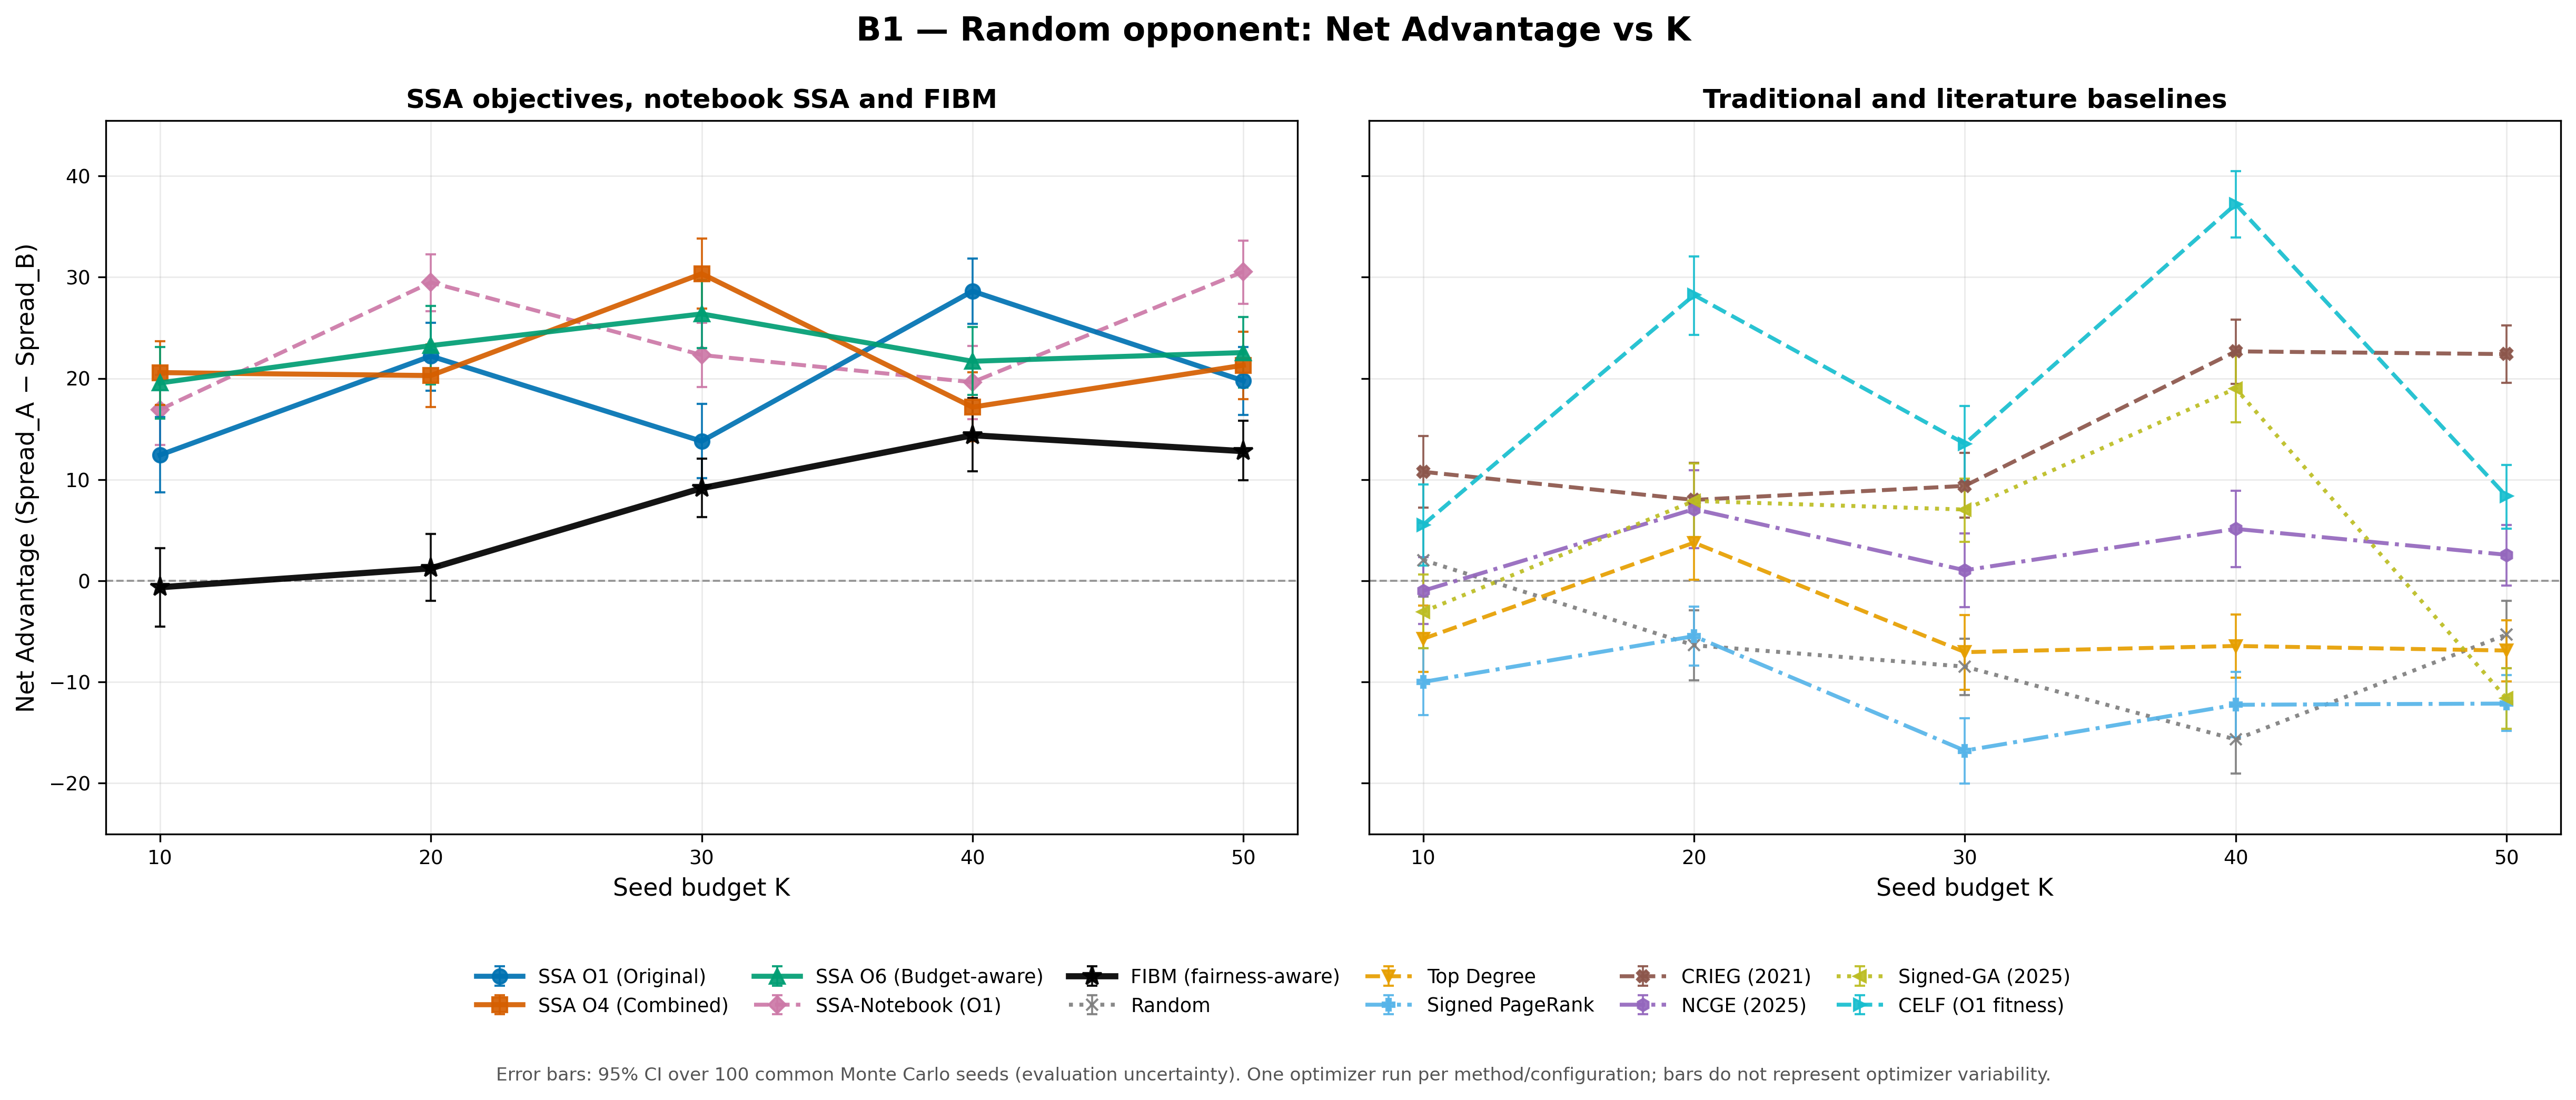

/home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness/figures/notebook_1000/Net_Advantage_B2.png


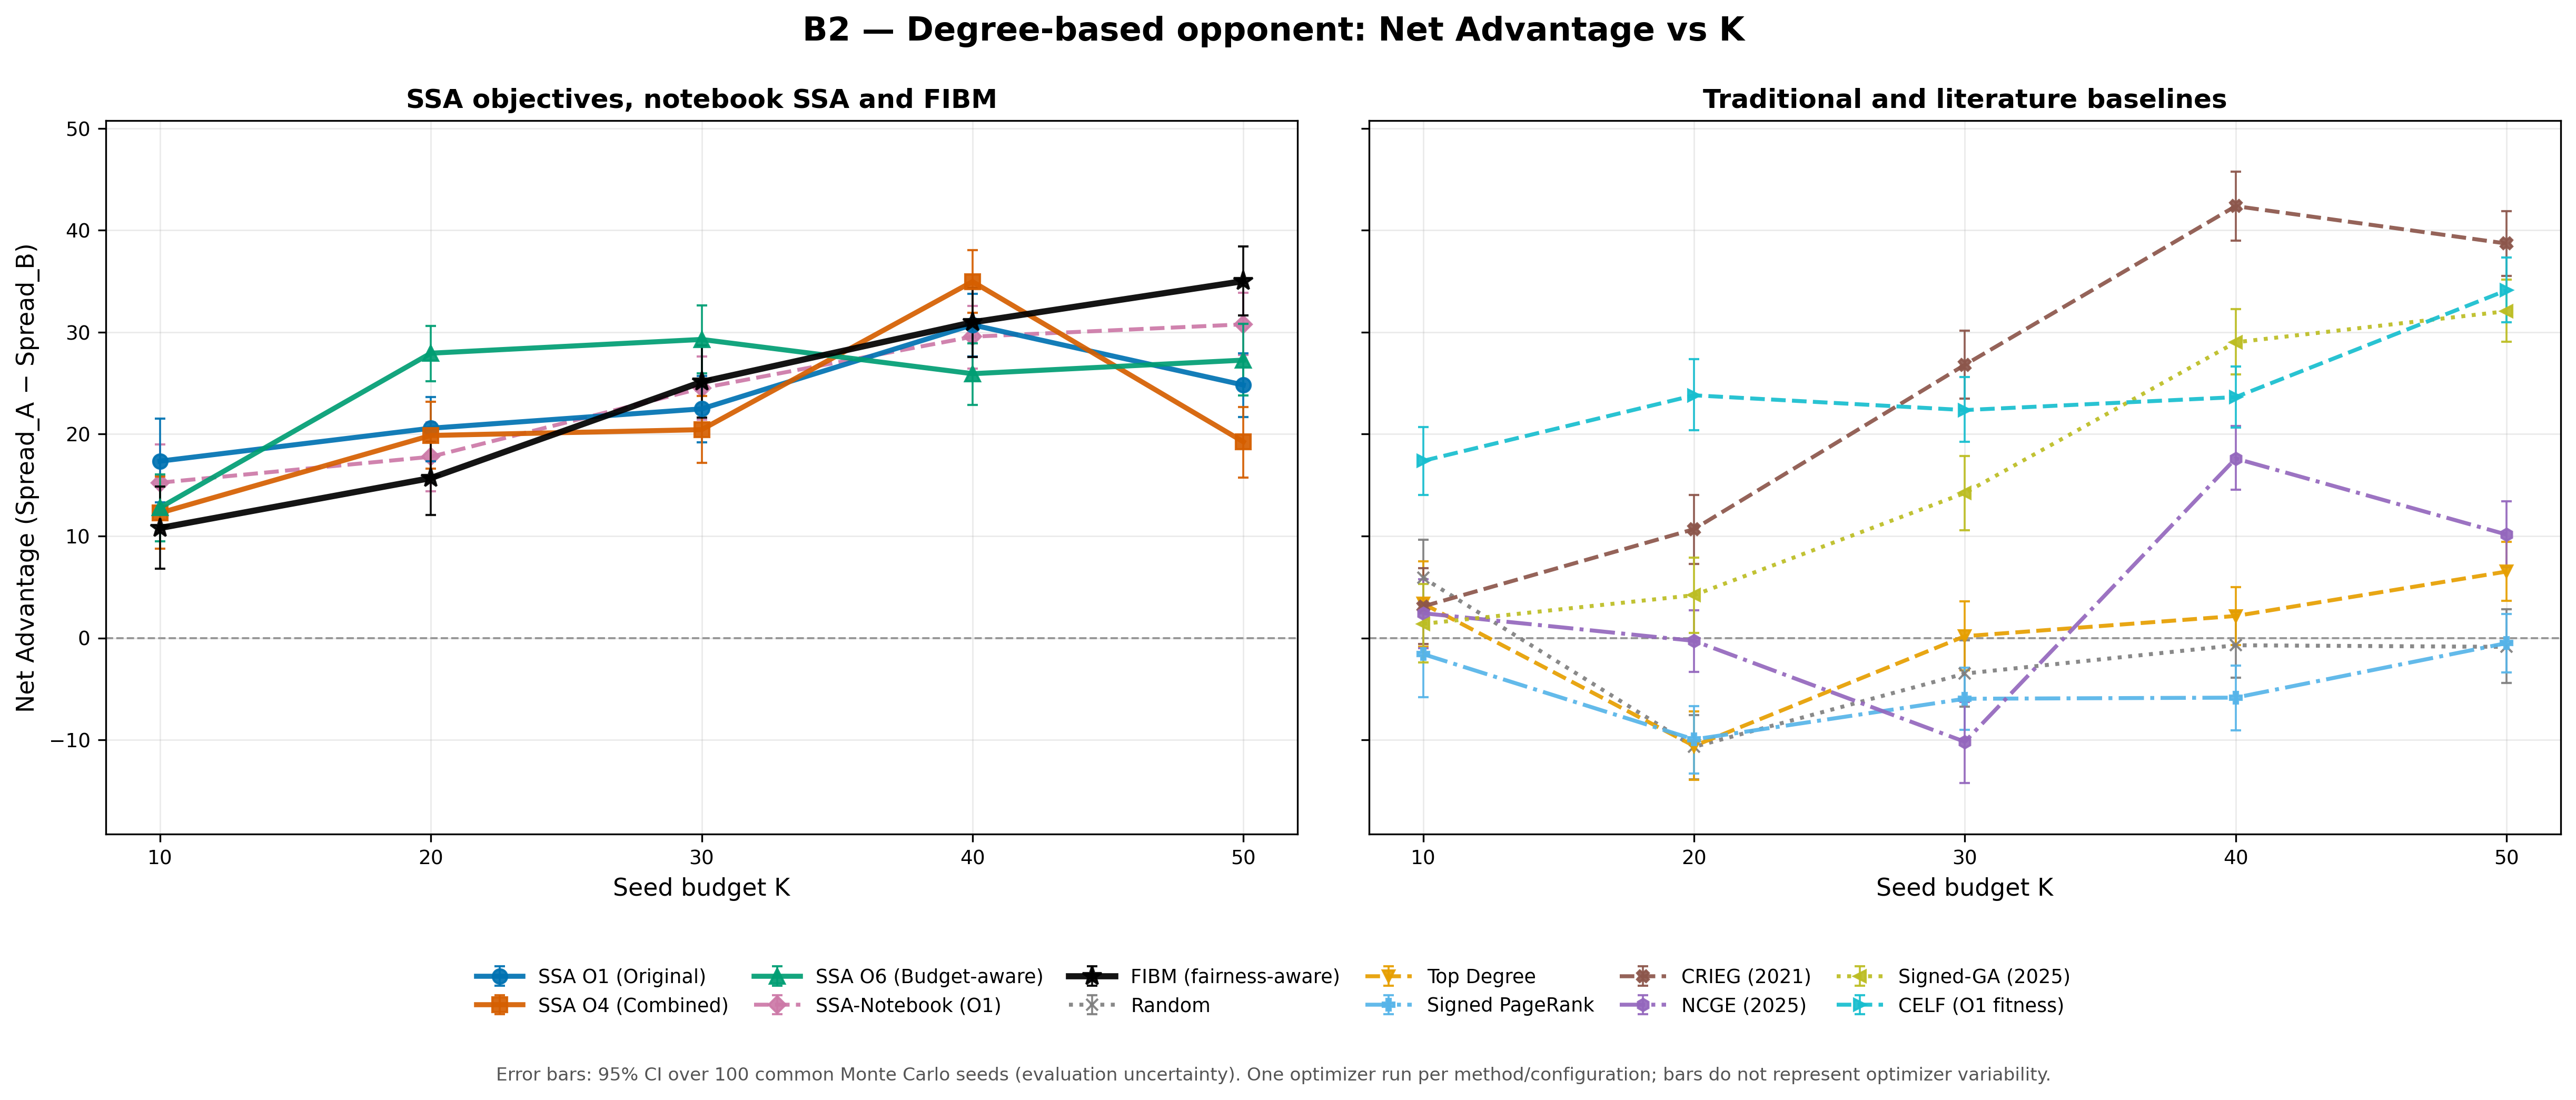

/home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness/figures/notebook_1000/Net_Advantage_B3.png


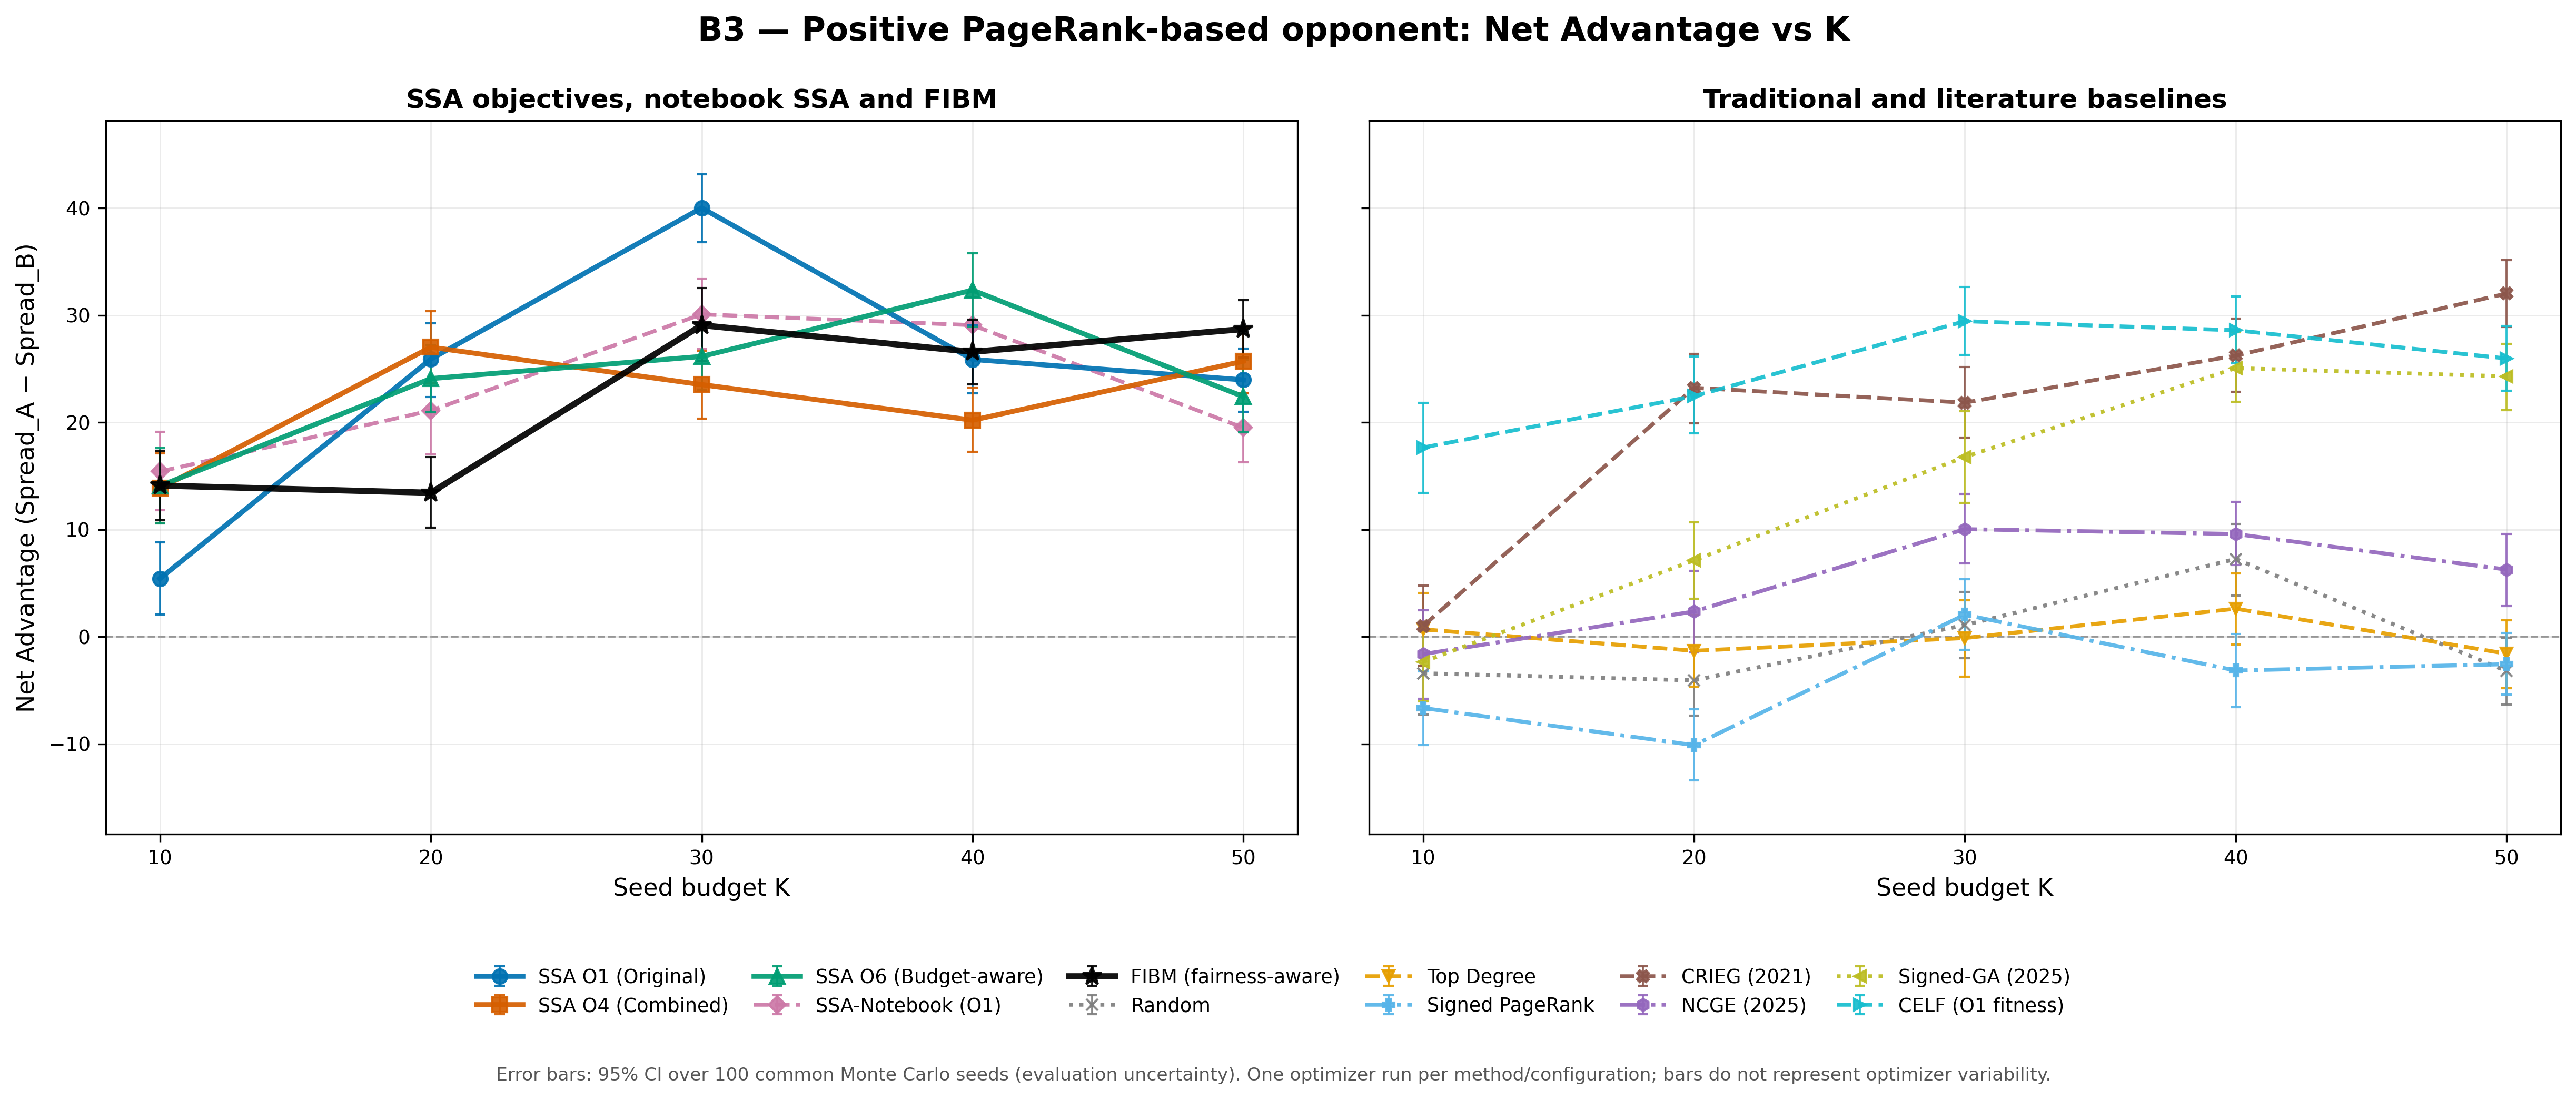

/home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness/figures/notebook_1000/Net_Advantage_B4.png


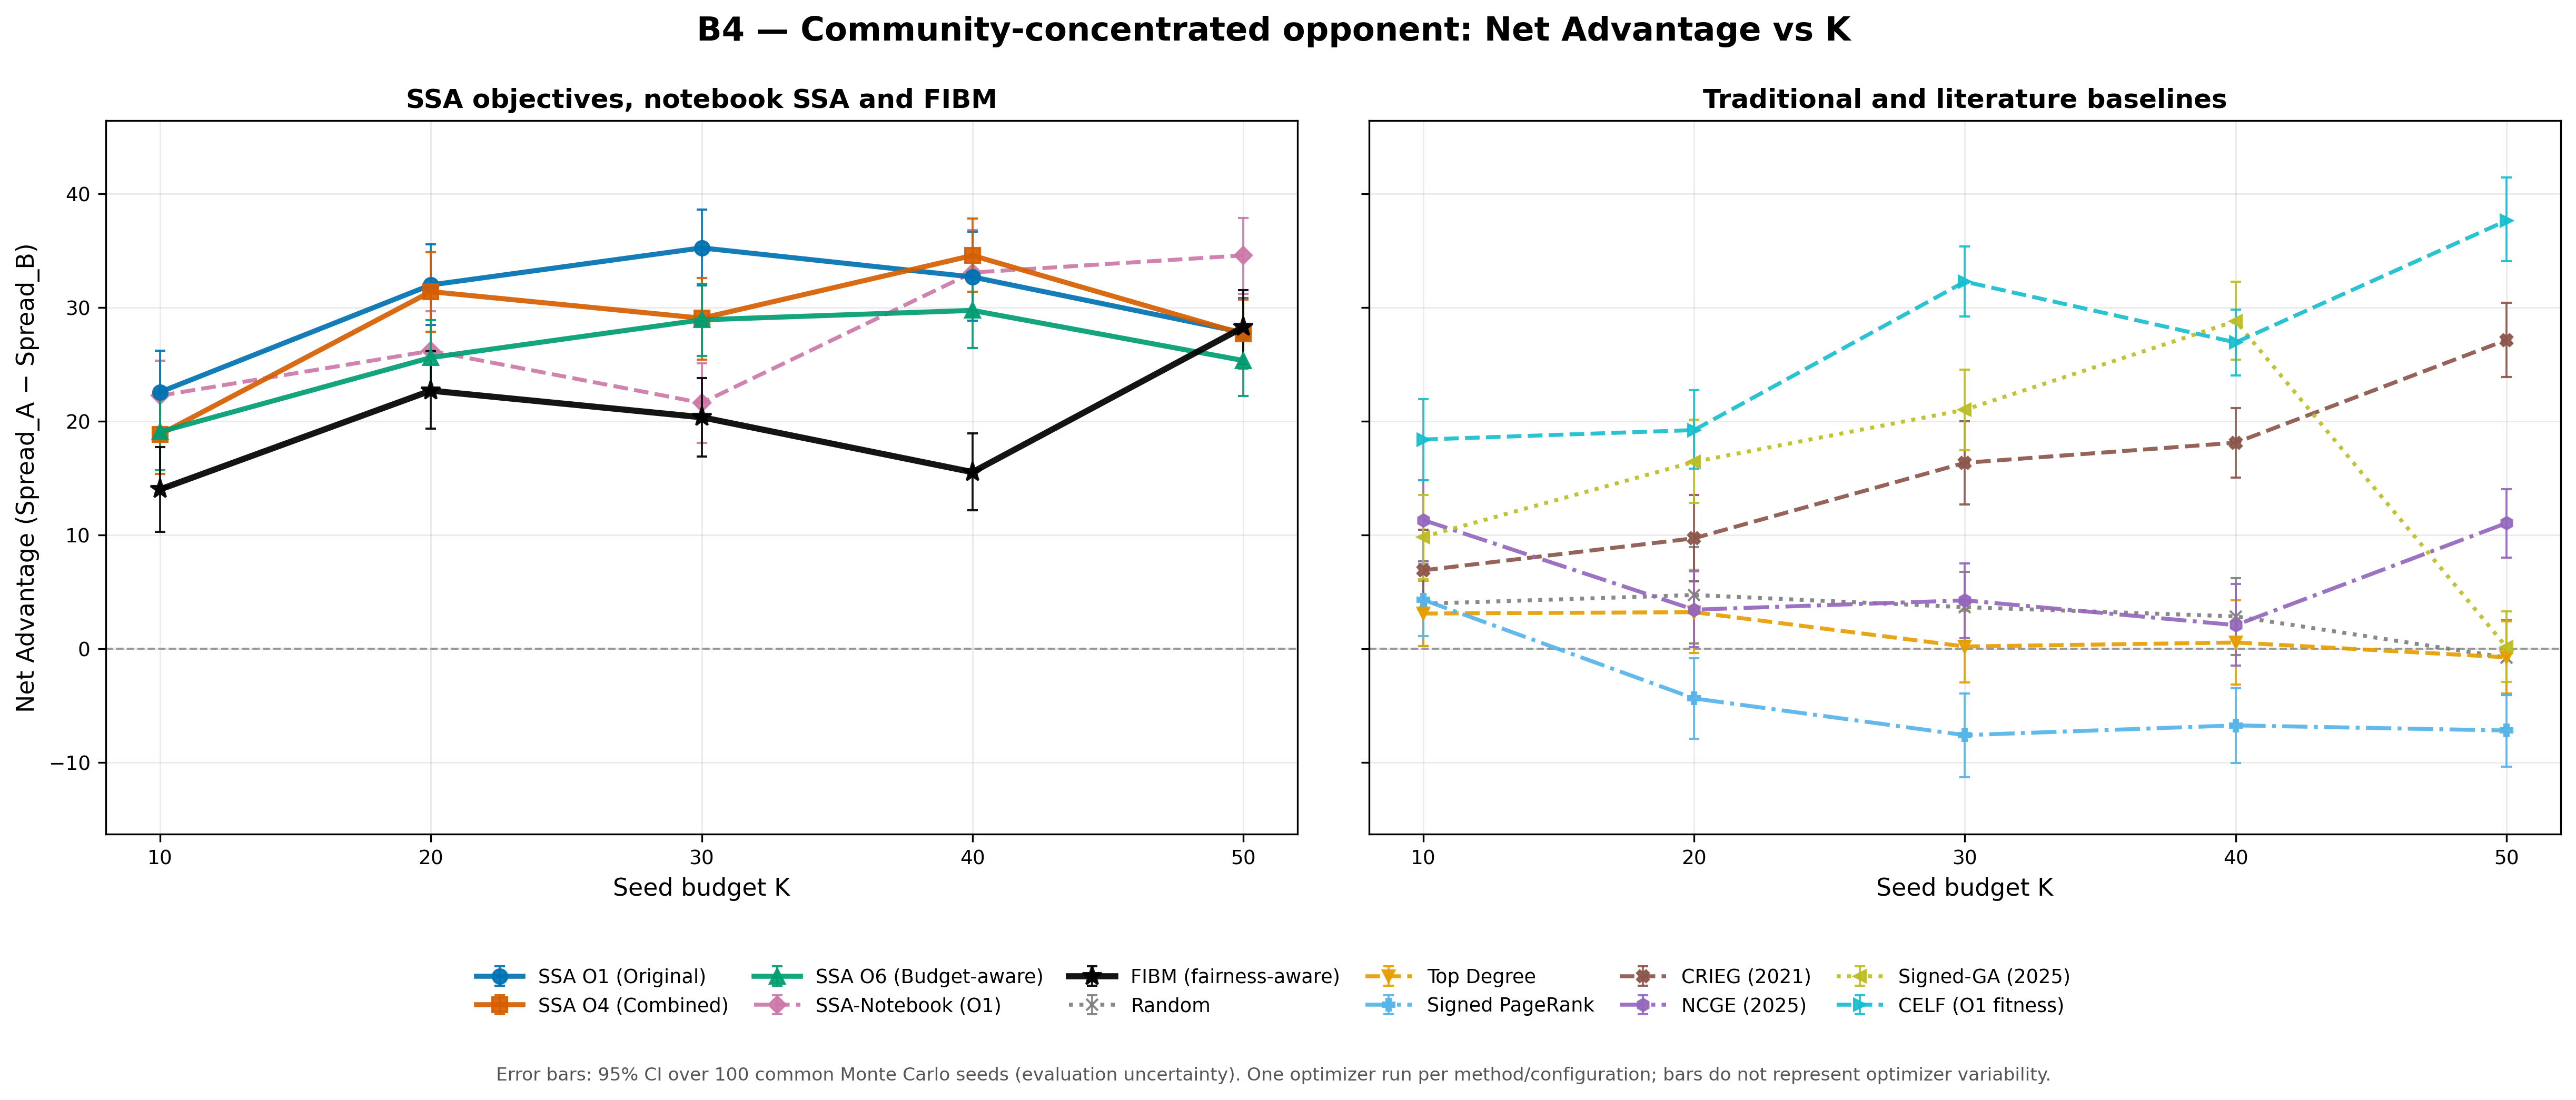

In [20]:
COLORS = na.METHOD_COLORS
MARKERS = na.METHOD_MARKERS
LINESTYLES = na.METHOD_LINESTYLES
LABELS = na.METHOD_LABELS
FOCUS = na.FOCUS_METHODS
BASELINES = na.BASELINE_METHODS

def _plot_panel(ax, data, methods, scenario):
    for method_id in methods:
        sub = data[(data["method_id"] == method_id) & (data["scenario"] == scenario)].sort_values("K")
        if sub.empty:
            continue
        y = sub["net_advantage"].to_numpy(float)
        lo = sub["net_advantage_ci_low"].to_numpy(float)
        hi = sub["net_advantage_ci_high"].to_numpy(float)
        yerr = np.vstack([y - lo, hi - y])
        lw = 2.8 if method_id == "FIBMM" else (2.3 if method_id in na.SSA_METHODS else 1.8)
        ms = 9 if method_id == "FIBMM" else (6.5 if method_id in na.SSA_METHODS else 5.5)
        ax.errorbar(
            sub["K"].to_numpy(int), y, yerr=yerr,
            color=COLORS[method_id], marker=MARKERS[method_id],
            linestyle=LINESTYLES[method_id], linewidth=lw, markersize=ms,
            capsize=2.5, elinewidth=0.9, alpha=0.92, label=LABELS[method_id],
            zorder=3 if method_id in na.SSA_METHODS + ["FIBMM"] else 2,
        )
    ax.axhline(0, color="#333333", linestyle="--", linewidth=0.9, alpha=0.55, zorder=1)
    ax.set_xticks(config["k_values"])
    ax.set_xticklabels([str(k) for k in config["k_values"]])
    ax.set_xlabel("Seed budget K")
    ax.grid(True, which="major", alpha=0.25, linewidth=0.7)

def plot_scenario(sid, data, outdir):
    fig, axes = plt.subplots(1, 2, figsize=(16.8, 7.0), sharey=True)
    _plot_panel(axes[0], data, FOCUS, sid)
    _plot_panel(axes[1], data, BASELINES, sid)
    axes[0].set_title("SSA objectives, notebook SSA and FIBM", fontsize=12, fontweight="bold")
    axes[1].set_title("Traditional and literature baselines", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Net Advantage (Spread_A − Spread_B)")
    all_lo = min(float(data[data["scenario"] == sid]["net_advantage_ci_low"].min()),
                 float(data[data["scenario"] == sid]["net_advantage"].min()))
    all_hi = max(float(data[data["scenario"] == sid]["net_advantage_ci_high"].max()),
                 float(data[data["scenario"] == sid]["net_advantage"].max()))
    pad = max(5.0, 0.08 * (all_hi - all_lo))
    axes[0].set_ylim(all_lo - pad, all_hi + pad)
    handles, labels = [], []
    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        handles += h
        labels += l
    order = {LABELS[m]: i for i, m in enumerate(na.METHOD_ORDER)}
    pairs = sorted(zip(labels, handles), key=lambda x: order.get(x[0], 99))
    labels = [p[0] for p in pairs]
    handles = [p[1] for p in pairs]
    fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False,
               bbox_to_anchor=(0.5, 0.055), fontsize=8.8, handlelength=2.4, columnspacing=1.3)
    fig.suptitle(f"{sid} — {na.SCENARIO_TITLES[sid]}: Net Advantage vs K",
                 fontsize=15, fontweight="bold", y=0.975)
    fig.text(0.5, 0.012,
             "Error bars: 95% CI over 100 common Monte Carlo seeds (evaluation uncertainty). "
             "One optimizer run per method/configuration; bars do not represent optimizer variability.",
             ha="center", fontsize=8.3, color="#555555")
    fig.subplots_adjust(left=0.06, right=0.985, top=0.88, bottom=0.235, wspace=0.06)
    path = outdir / f"Net_Advantage_{sid}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return path

notebook_figure_paths = [plot_scenario(sid, results_df, NOTEBOOK_FIG_DIR) for sid in config["scenarios"]]
for path in notebook_figure_paths:
    print(path)
    display(Image(filename=str(path), width=1200))


## 23. Findings and interpretation

### Overall

- **SSA-Notebook** has the highest mean Net Advantage: **24.483**.
- **SSA O6** is second: **24.218**.
- **SSA O1** is third: **24.212**.
- **CELF** is **23.638**; **SSA O4** is **23.416**.
- The mean differences among these five methods are small (about 1.07 between the top and fifth).
- **No method dominates.** SSA O1, SSA O4, CELF each have **4 strict wins**; SSA O6 has **3**, SSA-Notebook has **2**, and CRIEG has **3**.
- Only **4 of 20** winner-vs-runner-up paired 95% intervals exclude zero. Most per-cell rankings are descriptive, not decisive.

### SSA vs the traditional baselines

All three SSA variants beat Random, Top Degree, Signed PageRank and NCGE in every cell. They beat Signed-GA in 17–18 of 20 cells.

The real contests are CELF and CRIEG:

- O1 vs CELF: **11W/9L**
- O6 vs CELF: **11W/9L**
- O4 vs CELF: **8W/12L**
- O1 vs CRIEG: **14W/6L**
- O6 vs CRIEG: **15W/5L**
- O4 vs CRIEG: **13W/7L**

CELF wins B1 K=40, B2 K=10, B3 K=10 and B4 K=50. CRIEG wins B2 K=40, B2 K=50 and B3 K=50. These are genuine opponent- and K-dependent reversals, not a clean SSA sweep.

### FIBM

FIBM's mean Net Advantage is **18.363**. Its mean Blocked_B is **19.475**, slightly higher than the SSA variants (about 17.8), so it improves blocking on average. Its Spread_A is lower, which is why its Net Advantage is lower. Internal FIBM fairness estimates have mean Π = **0.708** and mean τ = **0.690**.

FIBM wins no cell outright on Net Advantage, but it is competitive in several B2/B3/B4 cells. It is a defensible fairness baseline, not a Net-Advantage optimizer.

### K and scenario sensitivity

- SSA O1 is strongest in B3/B4 (24.23/30.07 mean).
- SSA O6 is strongest in B2 (24.64 mean).
- SSA-Notebook is strongest in B1 (23.78 mean).
- CELF is strongest in B3/B4 (24.82/26.90 mean).
- CRIEG is strongest in B2 (24.33 mean) and wins B2 K=40/50.
- The ranking changes with K: SSA-Notebook leads at K=50 (28.85), while SSA O1/O6 are stronger at K=20–40.

### Runtime

SSA is the cheapest strong method (~0.20 s per cell). CELF is ~0.61 s, NCGE ~0.70 s, Signed-GA ~2.66 s and FIBM ~3.51 s. CELF uses about 639 objective evaluations per cell versus 132 for SSA; its competitive mean is not free.


## 24. Limitations

1. **One optimizer run per method/configuration.** The 100 final Monte Carlo runs measure evaluation uncertainty, not between-optimizer-run variability.
2. **B1–B4 are not replicates.** They are four deliberately different opponent strategies; no pooled significance test across scenarios is claimed.
3. **Synthetic network.** Results are conditional on this 1,000-node synthetic design and the reversed influence convention.
4. **FIBM adaptation.** FIBM's selection uses a positive-edge CIC surrogate; final evaluation uses the signed finite-contact Maki–Thompson model. The CRP budget is capped at 100,000 per configuration for this 1,000-node run.
5. **CELF and NCGE use O1 fitness**, not Net Advantage.
6. **Literature adaptations.** CRIEG, NCGE and Signed-GA were adapted to this signed competitive setting.
7. **CELF + Local Search is excluded** because it is swap-based post-processing.
8. **The 5,000-node benchmark is a different experiment.** Its results are not mixed with this 1,000-node run.


## 25. Conclusion and recommendation

On the 1,000-node synthetic graph, the SSA variants, CELF and SSA-Notebook form a tight top group. **SSA-Notebook has the highest mean Net Advantage (24.483), but SSA O1, SSA O4 and CELF each have 4 strict wins, and SSA O6 has 3; SSA-Notebook has 2.** This is a clear warning against choosing a method from the overall mean alone.

For the next research stage:

1. Treat **SSA O1 and SSA O6** as the primary SSA candidates; both have means around 24.2 and 3–4 strict wins.
2. Keep **CELF** as the primary cheap baseline; it is within 0.85 mean Net Advantage of the top method and wins four cells.
3. Keep **CRIEG** as a serious literature baseline on this smaller graph; it wins B2 K=40/50 and B3 K=50.
4. Retain **FIBM** as the fairness baseline. It improves Blocked_B slightly but does not win on Net Advantage.
5. Repeat the optimizer with independent random seeds before treating any ranking as stable; the top-group differences are small and only four winner-vs-runner-up intervals exclude zero.

The 5,000-node benchmark remains a separate experiment with different results; its files are not mixed with this 1,000-node run.


In [21]:
print("=" * 78)
print("Notebook reproducibility summary")
print("=" * 78)
print("Experiment directory:", EXPERIMENT_DIR)
print("Configuration:", CONFIG_PATH)
print("Network file SHA-256:", network_meta["file_sha256"])
print("Influence semantic SHA-256:", network_meta["influence_semantic_sha256"])
print("Influence direction:", network_meta["influence_direction"])
print("Rows loaded:", len(results_df), "| methods:", results_df["method_id"].nunique())
print("Expected cells:", reuse_audit["expected_cells"], "| present:", reuse_audit["present_cells"],
      "| missing:", len(reuse_audit["missing_cells"]))
print("Signature mismatches:", len(reuse_audit["signature_mismatches"]),
      "| bad MC files:", len(reuse_audit["mc_bad"]),
      "| opponent-inconsistent cells:", len(reuse_audit["b_inconsistent"]))
print("Execution mode:", EXECUTION_MODE)
print("Simulation launched during this notebook run:", SIMULATION_LAUNCHED)
print("Notebook figures:", NOTEBOOK_FIG_DIR)


Notebook reproducibility summary
Experiment directory: /home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness
Configuration: /home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness/config/benchmark_1000_synthetic_config.json
Network file SHA-256: 659d4fa65a3904c96e5653c16f3357b95a43a00440844157b203eb0d3e3087b5
Influence semantic SHA-256: 0c0f4e1f1d8a3abc0e2765941e94cfe233efbe32246c5b56c960f0c1ee7f7197
Influence direction: reverse_of_trust (target_to_source)
Rows loaded: 240 | methods: 12
Expected cells: 240 | present: 240 | missing: 0
Signature mismatches: 0 | bad MC files: 0 | opponent-inconsistent cells: 0
Execution mode: load_existing
Simulation launched during this notebook run: False
Notebook figures: /home/kushagragarg/im/IM_Experiment_Starter/IM_Synthetic_Experiment/experiments/benchmark_ssa_baselines_fairness/figures/notebook_1000
